# Caminho Livre · Análise de dados

**Data Science & Statistical Computing** · Global Solution 2026.2 (CitizenTech) · Grupo OctoFlow · 2ESPV

O Caminho Livre é um mapa colaborativo para quem anda a pé: o usuário avisa problemas na rua (degrau, buraco, calçada quebrada, rua escura, assalto, alagamento) e o app sugere uma **rota que desvia dos alertas**, com **peso maior à noite para os alertas de segurança** (hoje fixo entre 19h e 6h, RF09) e **validade de 15 dias** para alertas sem confirmação (RF14).

Esta é uma **entrega isolada**: ela não se conecta ao banco, à API nem à rota. Usamos dados públicos reais de São Paulo para testar duas hipóteses ligadas ao tema do app e, no fim, descrevemos como os resultados **poderiam** calibrar a solução no futuro.

| Parte | Hipótese | Base de dados |
|---|---|---|
| **A** (principal) | **H1.** Roubos e furtos a pedestres se concentram entre 19h e 23h | SSP-SP · Dados Criminais 2025 |
| **B** (complementar) | **H3.** As reclamações de calçada se concentram em algumas regiões da cidade | Prefeitura de SP · SP156 2025 |

> A hipótese 2 do README (ruas com reclamação de iluminação têm mais crimes) **não pôde ser testada**: os dados abertos do SP156 de 2025 não têm nenhuma categoria de iluminação pública. No lugar, a seção A.5 testa a mesma ideia ("a escuridão aumenta o risco?") com um experimento natural usando o horário do pôr do sol.

### Resumo dos resultados

| Pergunta | Resultado |
|---|---|
| **H1 · roubo** | **Confirmada.** 35,0% dos roubos a pedestres acontecem entre 19h e 23h, contra 20,8% se não houvesse concentração (1,68 vez; p < 0,001). |
| **H1 · furto** | **Fraca.** 22,4% (1,07 vez): diferença estatística, mas sem relevância prática. O furto acompanha o movimento do dia. |
| **Escuridão ou relógio?** | **Escuridão.** Às 18h há mais roubos nos dias em que já está escuro (razão de chances 1,22; p < 0,001). Às 20h, que é sempre noite, não há diferença. |
| **Tamanho do peso noturno** | Por hora, o risco de roubo no escuro é **1,43 vez** o do dia (IC 95%: 1,40 a 1,45). |
| **H3 · calçada** | **Confirmada.** A fatia de pedidos de calçada varia **3,6 vezes** entre as subprefeituras (p < 0,001), mais alta nas centrais. |
| **Validade dos alertas** | Só **6%** dos pedidos de obstáculo na calçada são resolvidos em 15 dias, que é a validade de um alerta sem confirmação no app. |

Detalhes, limitações e possíveis usos no app estão na **Conclusão**, no fim do notebook (e em `conclusao.md`).

## 0. Configuração

Para rodar: `pip install -r requirements.txt` e abra este notebook **de dentro da pasta `data-science/`**. Os extratos de dados já estão em `dados/` (como foram gerados está na seção A.1 e em `dados/README.md`).

In [1]:
from pathlib import Path
import datetime as dt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FuncFormatter
from scipy import stats
from scipy.stats.contingency import association, odds_ratio
from astral import Observer
from astral.sun import sun

DADOS = Path("dados")
GRAFICOS = Path("graficos")
GRAFICOS.mkdir(exist_ok=True)

# Cores (paleta testada para daltonismo) e estilo dos gráficos
AZUL, LARANJA = "#2a78d6", "#eb6834"          # Roubo = azul, Furto = laranja (em todos os gráficos)
TINTA, TINTA_2, TINTA_SUAVE = "#0b0b0b", "#52514e", "#898781"
FUNDO, FAIXA, GRADE, CINZA = "#fcfcfb", "#f0efec", "#e1e0d9", "#c3c2b7"
AZUIS = LinearSegmentedColormap.from_list("azuis", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": CINZA, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE, "font.size": 11,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def salvar(fig, nome):
    # Salva o gráfico em graficos/ (PNG) para usar no README e no pitch
    fig.savefig(GRAFICOS / nome)


def pct(x, casas=1):
    # 0.3506 -> '35,1%'
    return f"{x * 100:.{casas}f}%".replace(".", ",")


def fmt_p(p):
    # p-valor legível: valores minúsculos viram '< 0,001'
    return "< 0,001" if p < 0.001 else f"= {p:.3f}".replace(".", ",")


def hhmm(horas):
    # 18.25 -> '18:15'
    minutos = round(horas * 60)
    return f"{minutos // 60:02d}:{minutos % 60:02d}"


def fonte(fig, texto):
    # Escreve a fonte dos dados logo abaixo de tudo o que já está desenhado na figura
    fig.canvas.draw()
    caixa = fig.get_tightbbox(fig.canvas.get_renderer())          # área ocupada, em polegadas
    fig.text(caixa.x0 / fig.get_figwidth(), caixa.y0 / fig.get_figheight() - 0.02, texto,
             fontsize=8.5, color=TINTA_SUAVE, va="top")

# Parte A · Segurança: a que horas os pedestres são roubados?

**Pergunta:** o risco de roubo e furto para quem anda a pé muda ao longo do dia? Se sim, o "peso noturno" do Caminho Livre faz sentido, e de que tamanho ele deveria ser?

## A.1 Dados e preparo

**Fonte:** Secretaria da Segurança Pública do Estado de São Paulo (SSP-SP), página *Estatística › Consultas – Base de Dados › SP Dados – Dados criminais › 2025* ([ssp.sp.gov.br/estatistica/consultas](https://www.ssp.sp.gov.br/estatistica/consultas)), arquivo `SPDadosCriminais_2025.xlsx` (atualizado pela SSP em 30/06/2026, baixado em 16/11/2026). São os microdados de boletins de ocorrência (BOs) **registrados em 2025** no estado inteiro: cada linha é uma natureza criminal de um BO, com data, hora, tipo de local, conduta e natureza apurada. A aba `CAMPOS_DA_TABELA_SPDADOS` do próprio arquivo explica cada coluna.

O script `dados/gerar_extratos.py` fez só o **recorte** e a **anonimização**:

* manteve as ocorrências na **cidade de São Paulo** com natureza apurada **ROUBO - OUTROS** ou **FURTO - OUTROS** (roubo e furto que não são de veículo, carga ou banco: é aqui que estão os crimes contra pedestres);
* trocou o número do BO por um **código pseudônimo** (hash), descartou **logradouro e número** e arredondou as coordenadas para ~100 m.

Toda a limpeza vem a seguir, passo a passo.

In [2]:
funil_extracao = pd.read_csv(DADOS / "funil_extracao.csv")
funil_extracao

,base,etapa,linhas
0,SSP,"1. linhas no arquivo original (estado de SP, 2...",1161132
1,SSP,2. ocorridas na cidade de São Paulo,468052
2,SSP,3. natureza ROUBO - OUTROS ou FURTO - OUTROS (...,346702
3,SP156,sp156_2025_1tri.csv: linhas no arquivo,1048575
4,SP156,sp156_2025_1tri.csv: linhas totalmente vazias ...,305671
5,SP156,sp156_2025_2tri.csv: linhas no arquivo,589980
6,SP156,sp156_2025_2tri.csv: linhas totalmente vazias ...,0
7,SP156,sp156_2025_3tri.csv: linhas no arquivo,501685
8,SP156,sp156_2025_3tri.csv: linhas totalmente vazias ...,0
9,SP156,sp156_2025_4tri.csv: linhas no arquivo,479701


In [3]:
ssp_bruto = pd.read_csv(DADOS / "ssp_roubos_furtos_capital_2025.csv.gz", dtype=str, keep_default_na=False)
print(f"{len(ssp_bruto):,} linhas x {ssp_bruto.shape[1]} colunas")
ssp_bruto.head(3)

346,702 linhas x 14 colunas


,ID_BO_PSEUDONIMO,DATA_REGISTRO,DATA_OCORRENCIA_BO,HORA_OCORRENCIA_BO,DESC_PERIODO,DESCR_TIPOLOCAL,DESCR_SUBTIPOLOCAL,BAIRRO,LATITUDE,LONGITUDE,NOME_DELEGACIA_CIRCUNCRIÇÃO,RUBRICA,DESCR_CONDUTA,NATUREZA_APURADA
0,4f64f7adbb94,2025-01-03 00:00:00,2025-01-03 00:00:00,01:31:53,NULL,Via Pública,Via Pública,LIBERDADE,-23.555,-46.635,01º D.P. SE,Furto (art. 155),Transeunte,FURTO - OUTROS
1,a19549789556,2025-01-03 00:00:00,2025-01-02 00:00:00,21:30:00,NULL,Via Pública,Via Pública,LIBERDADE,-23.564,-46.632,01º D.P. SE,Furto (art. 155),Interior de Veículo,FURTO - OUTROS
2,2cbdf7d89dfb,2025-01-03 00:00:00,2024-12-19 00:00:00,12:30:00,NULL,Condomínio Comercial,Lojas,CENTRO HISTÓRICO DE SÃO PAULO,-23.544,-46.633,01º D.P. SE,Furto (art. 155),Outros,FURTO - OUTROS


**Passo 1 · Nulos.** Na base da SSP, campo vazio vem escrito como o texto `"NULL"` (está no dicionário do arquivo). Trocamos por nulo de verdade para o pandas entender.

In [4]:
ssp = ssp_bruto.replace({"NULL": np.nan, "": np.nan})
nulos = ssp.isna().mean().sort_values(ascending=False)
nulos[nulos > 0].map(pct).to_frame("% de nulos")

,% de nulos
DESC_PERIODO,"57,9%"
HORA_OCORRENCIA_BO,"42,1%"
LATITUDE,"11,2%"
LONGITUDE,"11,2%"
BAIRRO,"0,1%"


`HORA_OCORRENCIA_BO` e `DESC_PERIODO` se completam: quando a vítima não sabe a hora exata, a SSP registra só o período (manhã, tarde, noite, madrugada). Isso é tratado no passo 5.

**Passo 2 · Quem é pedestre.** O rótulo de conduta "Transeunte" (pedestre) é usado de forma inconsistente: a maioria dos roubos de rua está com conduta genérica "Outros". Por isso definimos *roubo/furto a pedestre* como:

1. aconteceu em **via pública**;
2. conduta **"Transeunte"** ou **"Outros"** (sai: fios e cabos, interior de veículo, estabelecimento, residência etc.);
3. o subtipo de local **não** é dentro de veículo ou de transporte coletivo.

Na seção A.4 refazemos o teste só com a conduta "Transeunte", para ver se a conclusão muda.

In [5]:
etapas = [("extrato: capital, roubo/furto 'outros'", len(ssp))]

ssp = ssp[ssp["DESCR_TIPOLOCAL"] == "Via Pública"]
etapas.append(("1. aconteceu em via pública", len(ssp)))

print("Condutas registradas em via pública:")
print(ssp["DESCR_CONDUTA"].value_counts(dropna=False).head(8).to_string(), "\n")

ssp = ssp[ssp["DESCR_CONDUTA"].isin(["Transeunte", "Outros"])]
DENTRO_DE_VEICULO = ["Interior de Transporte Coletivo", "Veículo em movimento",
                     "Interior de Veículo Particular", "Interior de Veículo de Carga"]
ssp = ssp[~ssp["DESCR_SUBTIPOLOCAL"].isin(DENTRO_DE_VEICULO)]
etapas.append(("2. conduta de pedestre, fora de veículos", len(ssp)))

Condutas registradas em via pública:
DESCR_CONDUTA
Outros                             235399
Transeunte                          20294
Interior de Veículo                  6274
Fios e Cabos                         5399
Interior Transporte Coletivo         1373
Estabelecimento Comercial             458
Residência                            422
Aplicativo de Mobilidade Urbana       248 



**Passo 3 · Duplicatas.** Um mesmo BO pode aparecer duas vezes (por exemplo, registrado como furto **e** como roubo). Ficamos com uma linha por BO, priorizando o roubo, que é o crime mais grave.

In [6]:
repetidos = ssp["ID_BO_PSEUDONIMO"].duplicated(keep=False)
print(f"linhas de BOs que aparecem mais de uma vez: {repetidos.sum()}")
display(ssp.loc[repetidos, ["ID_BO_PSEUDONIMO", "NATUREZA_APURADA", "HORA_OCORRENCIA_BO"]]
        .sort_values("ID_BO_PSEUDONIMO").head(4))

# "ROUBO - OUTROS" vem antes de "FURTO - OUTROS" em ordem decrescente, então o roubo é o que fica
ssp = ssp.sort_values("NATUREZA_APURADA", ascending=False).drop_duplicates("ID_BO_PSEUDONIMO")
etapas.append(("3. uma linha por boletim", len(ssp)))

linhas de BOs que aparecem mais de uma vez: 56


,ID_BO_PSEUDONIMO,NATUREZA_APURADA,HORA_OCORRENCIA_BO
92467,07a513176a16,FURTO - OUTROS,10:30:00
92507,07a513176a16,ROUBO - OUTROS,10:30:00
31027,17f548060bec,FURTO - OUTROS,16:00:00
31060,17f548060bec,ROUBO - OUTROS,16:00:00


**Passo 4 · Datas.** O arquivo traz os BOs *registrados* em 2025, mas alguns relatam fatos de anos anteriores. Ficamos só com fatos de 2025, para que o período analisado tenha um calendário único (meses, dias da semana e pôr do sol).

In [7]:
ssp["data"] = pd.to_datetime(ssp["DATA_OCORRENCIA_BO"], errors="coerce").dt.normalize()
print("Ano do fato (top 5):", ssp["data"].dt.year.value_counts().head(5).to_dict())

ssp = ssp[ssp["data"].dt.year == 2025].copy()
etapas.append(("4. fato ocorrido em 2025", len(ssp)))

Ano do fato (top 5): {2025: 249680, 2024: 4184, 2023: 173, 2015: 171, 2022: 79}


**Passo 5 · Horário.** Convertemos a hora para número (0 a 23). Quem não informou a hora exata fica sem hora, mas guardamos o período informado.

In [8]:
hora = pd.to_datetime(ssp["HORA_OCORRENCIA_BO"], format="%H:%M:%S", errors="coerce")
ssp["hora"] = hora.dt.hour.astype("Int64")
ssp["minuto"] = hora.dt.minute.astype("Int64")

sem_hora = ssp["hora"].isna()
print(f"BOs sem hora exata: {sem_hora.sum():,} ({pct(sem_hora.mean())}). Período informado nesses casos:")
ssp.loc[sem_hora, "DESC_PERIODO"].value_counts(dropna=False).to_frame("BOs")

BOs sem hora exata: 88,202 (35,3%). Período informado nesses casos:


,BOs
DESC_PERIODO,
A tarde,26636
A noite,26225
Pela manhã,22045
De madrugada,12773
Em hora incerta,523


Quando a hora existe, ela costuma ser **estimada** pela vítima: há muito mais horários "redondos" do que o acaso explicaria. Por isso a análise é feita **por hora cheia** (19h, 20h...), e não por minuto.

In [9]:
com = ssp[ssp["hora"].notna()]
print(f"minuto = 00:            {pct((com['minuto'] == 0).mean())}  (se fosse ao acaso: {pct(1 / 60)})")
print(f"minuto múltiplo de 5:   {pct((com['minuto'] % 5 == 0).mean())}  (ao acaso: {pct(12 / 60)})")
print(f"exatamente 00:00:       {((com['hora'] == 0) & (com['minuto'] == 0)).sum():,} BOs (possível 'hora não informada'; ficam na hora 0)")

minuto = 00:            33,9%  (se fosse ao acaso: 1,7%)
minuto múltiplo de 5:   85,1%  (ao acaso: 20,0%)
exatamente 00:00:       1,452 BOs (possível 'hora não informada'; ficam na hora 0)


**Passo 6 · Colunas derivadas.** Tipo (roubo ou furto), dia da semana, mês e período do dia. Para o período usamos as mesmas faixas de 6 horas do campo `DESC_PERIODO` (madrugada 0h–6h, manhã 6h–12h, tarde 12h–18h, noite 18h–24h). Há também uma grafia diferente ("de madrugada", minúsculo) que unificamos.

In [10]:
def periodo_da_hora(h):
    if h < 6:
        return "De madrugada"
    if h < 12:
        return "Pela manhã"
    if h < 18:
        return "A tarde"
    return "A noite"


ssp["tipo"] = ssp["NATUREZA_APURADA"].map({"ROUBO - OUTROS": "Roubo", "FURTO - OUTROS": "Furto"})
ssp["dia_semana"] = ssp["data"].dt.dayofweek          # 0 = segunda ... 6 = domingo
ssp["mes"] = ssp["data"].dt.month
ssp["periodo"] = ssp["DESC_PERIODO"].replace({"de madrugada": "De madrugada", "Em hora incerta": np.nan})
ssp.loc[~sem_hora, "periodo"] = ssp.loc[~sem_hora, "hora"].astype(int).map(periodo_da_hora)

com_hora = ssp[ssp["hora"].notna()].copy()
com_hora["hora"] = com_hora["hora"].astype(int)

etapas.append(("   ...destes, com hora exata", len(com_hora)))
pd.DataFrame(etapas, columns=["etapa do preparo", "BOs"])

,etapa do preparo,BOs
0,"extrato: capital, roubo/furto 'outros'",346702
1,1. aconteceu em via pública,270444
2,"2. conduta de pedestre, fora de veículos",254472
3,3. uma linha por boletim,254444
4,4. fato ocorrido em 2025,249680
5,"...destes, com hora exata",161478


In [11]:
pd.crosstab(ssp["tipo"], ssp["hora"].notna().map({True: "com hora exata", False: "só período"}), margins=True, margins_name="total")

hora,com hora exata,só período,total
tipo,,,
Furto,85621,80011,165632
Roubo,75857,8191,84048
total,161478,88202,249680


## A.2 Análise exploratória

Como as ocorrências se distribuem ao longo das 24 horas? Para comparar roubo e furto (que têm totais diferentes), usamos a **porcentagem** de cada tipo em cada hora.

In [12]:
por_hora = pd.crosstab(com_hora["hora"], com_hora["tipo"])[["Roubo", "Furto"]]
pct_hora = por_hora / por_hora.sum() * 100
pct_hora.round(1).T

hora,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
tipo,,,,,,,,,,,,,,,,,,,,,
Roubo,3.0,2.4,2.0,2.1,4.4,5.4,3.9,3.5,2.9,2.6,...,3.5,3.3,3.5,3.9,5.1,6.7,7.7,7.5,7.1,6.0
Furto,3.0,2.8,3.3,3.9,2.7,2.3,2.5,3.3,3.6,4.0,...,5.3,5.3,4.9,5.2,5.9,6.2,5.1,4.1,3.5,3.4


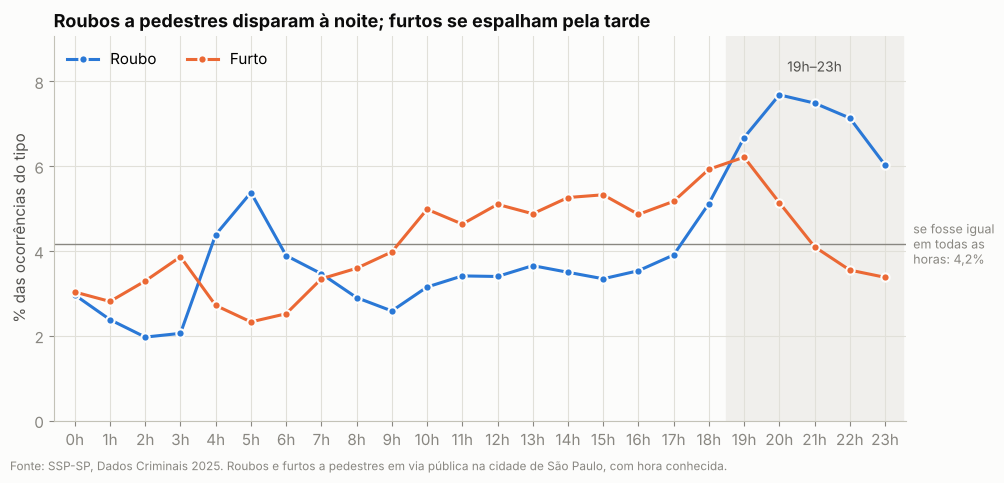

In [13]:
fig, ax = plt.subplots(figsize=(11, 5))
topo = pct_hora.to_numpy().max()
ax.axvspan(18.5, 23.5, color=FAIXA, zorder=0)
ax.text(21, topo + 0.55, "19h–23h", ha="center", color=TINTA_2, fontsize=10)
ax.axhline(100 / 24, color=TINTA_SUAVE, linewidth=1)
ax.text(23.8, 100 / 24, "se fosse igual\nem todas as\nhoras: 4,2%", color=TINTA_SUAVE, fontsize=9,
        va="center", clip_on=False)
for tipo, cor in [("Roubo", AZUL), ("Furto", LARANJA)]:
    ax.plot(pct_hora.index, pct_hora[tipo], color=cor, linewidth=2.2, marker="o", markersize=6,
            markeredgecolor=FUNDO, markeredgewidth=1.5, label=tipo)
ax.set_xticks(range(24), [f"{h}h" for h in range(24)])
ax.set_xlim(-0.6, 23.6)
ax.set_ylim(0, topo + 1.4)
ax.set_ylabel("% das ocorrências do tipo")
ax.set_title("Roubos a pedestres disparam à noite; furtos se espalham pela tarde")
ax.legend(loc="upper left", ncols=2)
fonte(fig, "Fonte: SSP-SP, Dados Criminais 2025. Roubos e furtos a pedestres em via pública na cidade de São Paulo, com hora conhecida.")
salvar(fig, "01_roubos_furtos_por_hora.png")
plt.show()

Os padrões são bem diferentes:

* **Roubo** (com violência ou ameaça) cresce a partir das 18h, tem o pico entre **19h e 22h** e cai de madrugada. Há um **segundo pico entre 4h e 6h**, horário de quem sai cedo para trabalhar, ainda no escuro.
* **Furto** (sem violência) acompanha o movimento de pessoas: sobe ao longo do dia, tem o pico no fim da tarde (18h–19h) e cai à noite.

O mapa de calor abaixo mostra que o padrão do roubo se repete em todos os dias da semana.

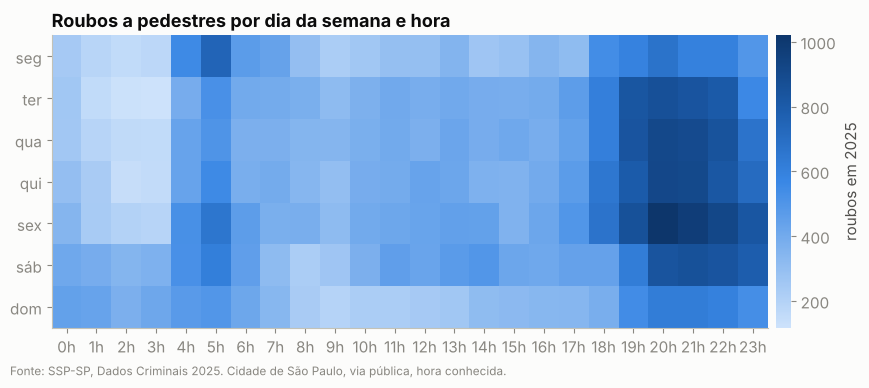

In [14]:
DIAS = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
roubos = com_hora[com_hora["tipo"] == "Roubo"].copy()
mapa = pd.crosstab(roubos["dia_semana"], roubos["hora"])

fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(mapa, cmap=AZUIS, aspect="auto")
ax.set_xticks(range(24), [f"{h}h" for h in range(24)])
ax.set_yticks(range(7), DIAS)
ax.grid(False)
ax.set_title("Roubos a pedestres por dia da semana e hora")
barra = fig.colorbar(im, ax=ax, pad=0.01)
barra.set_label("roubos em 2025")
barra.outline.set_visible(False)
fonte(fig, "Fonte: SSP-SP, Dados Criminais 2025. Cidade de São Paulo, via pública, hora conhecida.")
salvar(fig, "02_roubos_dia_semana_hora.png")
plt.show()

## A.3 Teste da hipótese H1

**H1:** roubos e furtos a pedestres se concentram entre 19h e 23h.

Se **não** houvesse concentração, cada hora teria a mesma fatia das ocorrências e a faixa 19h–23h (5 das 24 horas: 19h, 20h, 21h, 22h e 23h) ficaria com **5/24 = 20,8%**. Formalmente, para cada tipo:

* **H0:** p(19h–23h) = 20,8%  ·  **H1:** p(19h–23h) > 20,8%  ·  nível de significância **α = 0,05**.

Usamos três testes:

1. **Qui-quadrado de aderência** nas 24 horas: a distribuição é uniforme? Como a amostra é enorme, qualquer diferença mínima dá p-valor baixo, então olhamos também o **tamanho do efeito** (w de Cohen: 0,1 pequeno, 0,3 médio, 0,5 grande).
2. **Teste binomial exato** (unilateral) da fatia 19h–23h, com **intervalo de confiança de 95%** (Wilson).
3. **Qui-quadrado de independência** + **razão de chances**: o roubo é mais noturno que o furto?

In [15]:
aderencia = []
for tipo in ["Roubo", "Furto"]:
    observado = por_hora[tipo].to_numpy()
    teste = stats.chisquare(observado)       # H0: as 24 horas têm a mesma frequência
    aderencia.append({"tipo": tipo, "n": observado.sum(), "qui-quadrado": round(teste.statistic),
                      "graus de liberdade": 23, "p-valor": fmt_p(teste.pvalue),
                      "w de Cohen": round(np.sqrt(teste.statistic / observado.sum()), 2)})
pd.DataFrame(aderencia).set_index("tipo")

,n,qui-quadrado,graus de liberdade,p-valor,w de Cohen
tipo,,,,,
Roubo,75857,12211,23,"< 0,001",0.40
Furto,85621,5915,23,"< 0,001",0.26


In [16]:
P0 = 5 / 24
linhas = []
for tipo in ["Roubo", "Furto", "Roubo + furto"]:
    grupo = com_hora if tipo == "Roubo + furto" else com_hora[com_hora["tipo"] == tipo]
    n = len(grupo)
    k = int(grupo["hora"].between(19, 23).sum())
    teste = stats.binomtest(k, n, P0, alternative="greater")                         # teste unilateral (H1: p > 20,8%)
    ic = stats.binomtest(k, n).proportion_ci(confidence_level=0.95, method="wilson")  # intervalo de confiança bilateral
    linhas.append({"tipo": tipo, "n": n, "em 19h–23h": k, "observado": k / n,
                   "IC 95%": f"{pct(ic.low)} a {pct(ic.high)}", "esperado": P0,
                   "observado ÷ esperado": round(k / n / P0, 2), "p-valor": fmt_p(teste.pvalue)})
h1 = pd.DataFrame(linhas).set_index("tipo")
h1.assign(observado=h1["observado"].map(pct), esperado=h1["esperado"].map(pct))

,n,em 19h–23h,observado,IC 95%,esperado,observado ÷ esperado,p-valor
tipo,,,,,,,
Roubo,75857,26562,"35,0%","34,7% a 35,4%","20,8%",1.68,"< 0,001"
Furto,85621,19164,"22,4%","22,1% a 22,7%","20,8%",1.07,"< 0,001"
Roubo + furto,161478,45726,"28,3%","28,1% a 28,5%","20,8%",1.36,"< 0,001"


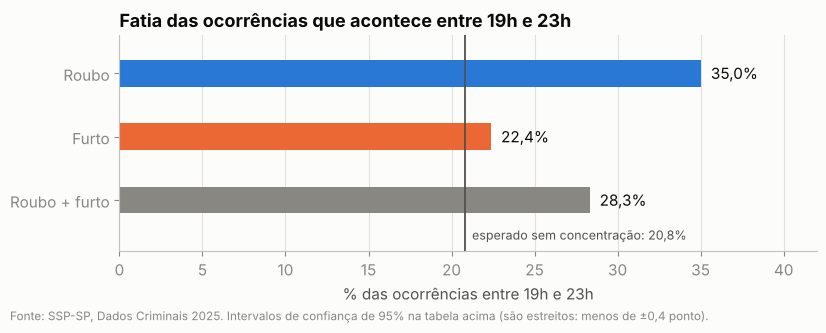

In [17]:
fig, ax = plt.subplots(figsize=(9, 2.8))
cores = {"Roubo": AZUL, "Furto": LARANJA, "Roubo + furto": TINTA_SUAVE}
for i, (tipo, linha) in enumerate(h1.iterrows()):
    ax.barh(i, linha["observado"] * 100, height=0.42, color=cores[tipo])
    ax.text(linha["observado"] * 100 + 0.6, i, pct(linha["observado"]), va="center", color=TINTA)
ax.axvline(P0 * 100, color=TINTA_2, linewidth=1.3)
ax.text(P0 * 100 + 0.4, 2.55, "esperado sem concentração: 20,8%", color=TINTA_2, fontsize=9, va="center")
ax.set_yticks(range(len(h1)), h1.index)
ax.set_ylim(2.8, -0.6)
ax.set_xlim(0, 42)
ax.set_xlabel("% das ocorrências entre 19h e 23h")
ax.grid(axis="y", visible=False)
ax.set_title("Fatia das ocorrências que acontece entre 19h e 23h")
fonte(fig, "Fonte: SSP-SP, Dados Criminais 2025. Intervalos de confiança de 95% na tabela acima (são estreitos: menos de ±0,4 ponto).")
salvar(fig, "03_teste_h1_faixa_19_23h.png")
plt.show()

In [18]:
faixa = com_hora["hora"].between(19, 23).map({True: "19h–23h", False: "outras horas"})
tabela = pd.crosstab(com_hora["tipo"], faixa).loc[["Roubo", "Furto"], ["19h–23h", "outras horas"]]
qui2, p, gl, _ = stats.chi2_contingency(tabela)
rc = odds_ratio(tabela.to_numpy())
ic = rc.confidence_interval(confidence_level=0.95)
display(tabela)
print(f"Qui-quadrado de independência = {qui2:,.0f} (gl = {gl}), p {fmt_p(p)}; "
      f"V de Cramér = {association(tabela.to_numpy(), method='cramer'):.2f}")
print(f"Razão de chances (roubo vs furto estar em 19h–23h) = {rc.statistic:.2f} "
      f"(IC 95%: {ic.low:.2f} a {ic.high:.2f})")

hora,19h–23h,outras horas
tipo,,
Roubo,26562,49295
Furto,19164,66457


Qui-quadrado de independência = 3,162 (gl = 1), p < 0,001; V de Cramér = 0.14
Razão de chances (roubo vs furto estar em 19h–23h) = 1.87 (IC 95%: 1.83 a 1.91)


**Interpretação**

* **Roubo: H1 confirmada com folga.** A fatia entre 19h e 23h é bem maior que os 20,8% esperados, com p-valor muito abaixo de 0,05, e o efeito é grande o bastante para importar na prática (veja a coluna *observado ÷ esperado*).
* **Furto: H1 só "passa" no papel.** O teste também rejeita H0, porque com quase 90 mil furtos até uma diferença pequena vira "significativa". Mas o tamanho do efeito é pequeno: o furto não é um crime noturno, ele acompanha o movimento de pessoas durante o dia.
* **Roubo × furto:** a chance de um roubo estar na faixa 19h–23h é bem maior que a de um furto (razão de chances acima de 1, com intervalo de confiança longe de 1).

Ou seja, **a hipótese vale para o crime violento (roubo), que é justamente o que o alerta "assalto" do Caminho Livre representa.**

## A.4 Checagens de robustez

O resultado depende das escolhas do preparo? Refazemos a conta em recortes diferentes:

* **só a conduta "Transeunte"**, o rótulo explícito de pedestre (passo 2);
* **dias úteis × fim de semana**;
* **BOs sem hora exata:** quem não sabia a hora informou só o período. Se esses casos fossem muito diferentes, ignorá-los poderia distorcer o resultado. Comparamos a distribuição por período dos dois grupos.

In [19]:
def fatia_19_23(df, tipo):
    sub = df[df["tipo"] == tipo]
    return pct(sub["hora"].between(19, 23).mean()), len(sub)


checagens = []
for nome, filtro in [("base principal", com_hora["tipo"].notna()),
                     ("só conduta 'Transeunte'", com_hora["DESCR_CONDUTA"] == "Transeunte"),
                     ("dias úteis (seg–sex)", com_hora["dia_semana"] <= 4),
                     ("fim de semana (sáb–dom)", com_hora["dia_semana"] >= 5)]:
    sub = com_hora[filtro]
    (r, nr), (f, nf) = fatia_19_23(sub, "Roubo"), fatia_19_23(sub, "Furto")
    checagens.append({"recorte": nome, "Roubo: % em 19h–23h": r, "n roubos": nr,
                      "Furto: % em 19h–23h": f, "n furtos": nf})
pd.DataFrame(checagens).set_index("recorte")

,Roubo: % em 19h–23h,n roubos,Furto: % em 19h–23h,n furtos
recorte,,,,
base principal,"35,0%",75857,"22,4%",85621
só conduta 'Transeunte',"33,0%",10093,"21,7%",6514
dias úteis (seg–sex),"36,0%",54756,"22,2%",63867
fim de semana (sáb–dom),"32,4%",21101,"22,8%",21754


In [20]:
ORDEM_PERIODOS = ["De madrugada", "Pela manhã", "A tarde", "A noite"]
comparacao = (ssp.dropna(subset=["periodo"])
                 .assign(grupo=lambda d: np.where(d["hora"].notna(), "com hora exata", "só período"))
                 .groupby(["tipo", "grupo"])["periodo"]
                 .value_counts(normalize=True)
                 .unstack()[ORDEM_PERIODOS])
comparacao.map(pct)

periodo              De madrugada Pela manhã A tarde A noite
tipo  grupo                                                 
Furto com hora exata        18,0%      23,1%   30,6%   28,3%
      só período            13,6%      25,7%   31,5%   29,2%
Roubo com hora exata        19,1%      19,4%   21,3%   40,1%
      só período            23,6%      20,1%   19,7%   36,5%

A concentração noturna do roubo aparece em todos os recortes, inclusive só com a conduta "Transeunte" e no fim de semana. Os BOs sem hora exata também têm a noite como período mais comum para roubo, então deixá-los de fora não cria o resultado.

## A.5 Escuridão ou relógio? Um experimento natural com o pôr do sol

A concentração noturna pode ter duas explicações: **o horário** (rotina das pessoas, saída do trabalho e da faculdade) ou **a escuridão** (menos visibilidade, ruas mais vazias). Elas se misturam, porque à noite é sempre escuro.

Mas há um horário em que dá para separar as duas: **as 18h**. Em São Paulo, o anoitecer (fim do crepúsculo civil) acontece por volta de **17h50 em junho** e **19h15 em dezembro**. Ou seja, às 18h30 é noite no inverno e ainda é dia no verão, **no mesmo horário do relógio**. Se a escuridão importa, as 18h devem ter **mais roubos nos dias em que já está escuro**.

Para não confundir com variações gerais entre os meses, comparamos com horários que **não mudam**: **12h–15h** (sempre dia) como base e **20h** (sempre noite) como teste de controle (placebo). Os horários do sol são calculados com a biblioteca `astral` para cada dia de 2025.

In [21]:
SAO_PAULO = Observer(latitude=-23.55, longitude=-46.63)
FUSO = dt.timezone(dt.timedelta(hours=-3))      # São Paulo não tem horário de verão desde 2019


def em_horas(momento):
    return momento.hour + momento.minute / 60 + momento.second / 3600


linhas = []
for dia in pd.date_range("2025-01-01", "2025-12-31"):
    s = sun(SAO_PAULO, date=dia.date(), tzinfo=FUSO)    # dawn, sunrise, noon, sunset, dusk
    linhas.append({"data": dia, "amanhecer": em_horas(s["dawn"]), "nascer_do_sol": em_horas(s["sunrise"]),
                   "por_do_sol": em_horas(s["sunset"]), "anoitecer": em_horas(s["dusk"])})
sol = pd.DataFrame(linhas).set_index("data")

MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
sol_mensal = sol.groupby(sol.index.month).mean()
sol_mensal.index = MESES
sol_mensal.map(hhmm).T

,jan,fev,mar,abr,mai,jun,jul,ago,set,out,nov,dez
amanhecer,05:09,05:30,05:46,05:57,06:10,06:21,06:22,06:07,05:40,05:10,04:50,04:50
nascer_do_sol,05:34,05:54,06:09,06:21,06:34,06:46,06:47,06:31,06:03,05:33,05:14,05:16
por_do_sol,18:57,18:46,18:21,17:52,17:32,17:28,17:38,17:50,18:01,18:12,18:29,18:49
anoitecer,19:23,19:10,18:44,18:15,17:57,17:53,18:02,18:14,18:24,18:35,18:54,19:15


In [22]:
REF = [12, 13, 14, 15]                             # horas sempre claras (base de comparação)
sol["escuro_as_18h30"] = sol["anoitecer"] < 18.5   # às 18h30 já é noite?
roubos["escuro_as_18h30"] = roubos["data"].map(sol["escuro_as_18h30"])
print(f"Dias de 2025 em que às 18h30 já é noite: {sol['escuro_as_18h30'].sum()} de {len(sol)}\n")


def teste_escuridao(hora_teste):
    sub = roubos[roubos["hora"].isin(REF + [hora_teste])]
    linhas_t = ["dias em que 18h30 já é noite", "dias em que 18h30 ainda é dia"]
    colunas_t = [f"roubos às {hora_teste}h", "roubos 12h–15h"]
    dia = sub["escuro_as_18h30"].map({True: linhas_t[0], False: linhas_t[1]})
    horario = (sub["hora"] == hora_teste).map({True: colunas_t[0], False: colunas_t[1]})
    t = pd.crosstab(dia, horario).loc[linhas_t, colunas_t]
    rc = odds_ratio(t.to_numpy())
    ic = rc.confidence_interval(confidence_level=0.95)
    _, p, _, _ = stats.chi2_contingency(t)
    return t, rc.statistic, ic, p


for hora_teste in [18, 20]:
    t, razao, ic, p = teste_escuridao(hora_teste)
    display(t)
    print(f"{hora_teste}h: razão de chances = {razao:.2f} (IC 95%: {ic.low:.2f} a {ic.high:.2f}), "
          f"qui-quadrado p {fmt_p(p)}\n")

Dias de 2025 em que às 18h30 já é noite: 188 de 365



hora,roubos às 18h,roubos 12h–15h
escuro_as_18h30,,
dias em que 18h30 já é noite,2198,5441
dias em que 18h30 ainda é dia,1684,5099


18h: razão de chances = 1.22 (IC 95%: 1.14 a 1.32), qui-quadrado p < 0,001



hora,roubos às 20h,roubos 12h–15h
escuro_as_18h30,,
dias em que 18h30 já é noite,3045,5441
dias em que 18h30 ainda é dia,2784,5099


20h: razão de chances = 1.02 (IC 95%: 0.96 a 1.09), qui-quadrado p = 0,460



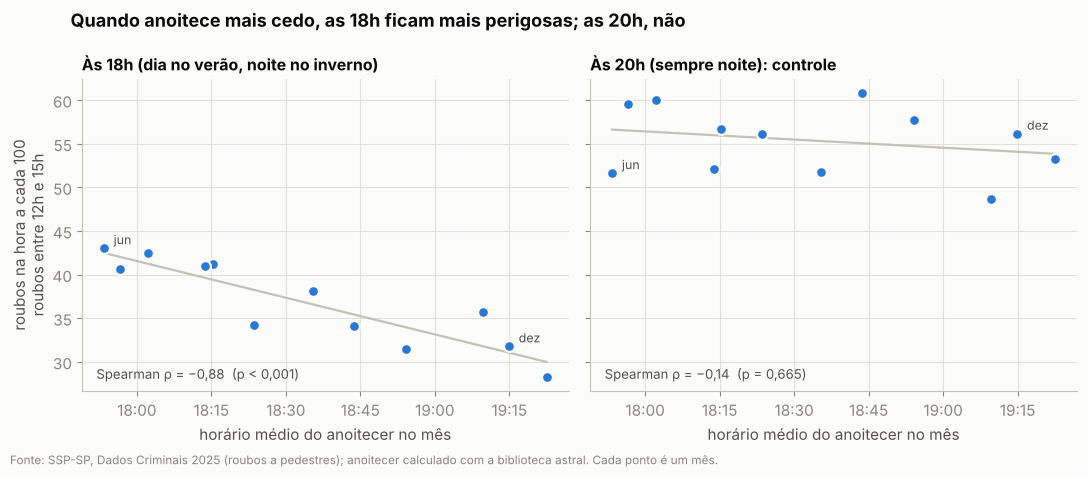

,anoitecer,roubos_18h,roubos_20h,roubos_12h_15h,18h a cada 100 (12h–15h),20h a cada 100 (12h–15h)
1,19.4,278,524,984,28.3,53.3
2,19.2,327,445,915,35.7,48.6
3,18.7,323,576,947,34.1,60.8
4,18.3,327,450,794,41.2,56.7
5,17.9,359,526,884,40.6,59.5
6,17.9,375,450,872,43.0,51.6
7,18.0,385,544,907,42.4,60.0
8,18.2,392,499,957,41.0,52.1
9,18.4,300,493,878,34.2,56.2
10,18.6,334,453,876,38.1,51.7


In [23]:
mensal = pd.DataFrame({
    "anoitecer": sol.groupby(sol.index.month)["anoitecer"].mean(),
    "roubos_18h": roubos[roubos["hora"] == 18].groupby("mes").size(),
    "roubos_20h": roubos[roubos["hora"] == 20].groupby("mes").size(),
    "roubos_12h_15h": roubos[roubos["hora"].isin(REF)].groupby("mes").size(),
})
mensal["18h a cada 100 (12h–15h)"] = mensal["roubos_18h"] / mensal["roubos_12h_15h"] * 100
mensal["20h a cada 100 (12h–15h)"] = mensal["roubos_20h"] / mensal["roubos_12h_15h"] * 100

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, coluna, titulo in [(eixos[0], "18h a cada 100 (12h–15h)", "Às 18h (dia no verão, noite no inverno)"),
                           (eixos[1], "20h a cada 100 (12h–15h)", "Às 20h (sempre noite): controle")]:
    x, y = mensal["anoitecer"], mensal[coluna]
    rho, p = stats.spearmanr(x, y)
    a, b = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, a * xs + b, color=CINZA, linewidth=1.6, zorder=1)
    ax.scatter(x, y, s=60, color=AZUL, edgecolor=FUNDO, linewidth=1.5, zorder=2)
    for mes in [6, 12]:
        ax.annotate(MESES[mes - 1], (x[mes], y[mes]), xytext=(7, 3), textcoords="offset points",
                    fontsize=9, color=TINTA_2)
    ax.set_title(titulo, fontsize=11.5)
    ax.text(0.03, 0.04, f"Spearman ρ = {rho:.2f}  (p {fmt_p(p)})".replace("ρ = -", "ρ = −").replace(".", ","),
            transform=ax.transAxes, fontsize=9.5, color=TINTA_2)
    ax.set_xticks(np.arange(18, 19.5, 0.25))                     # de 15 em 15 minutos
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: hhmm(v)))
    ax.set_xlabel("horário médio do anoitecer no mês")
eixos[0].set_ylabel("roubos na hora a cada 100\nroubos entre 12h e 15h")
fig.suptitle("Quando anoitece mais cedo, as 18h ficam mais perigosas; as 20h, não",
             x=0.07, ha="left", fontweight="bold", color=TINTA, fontsize=13)
fig.tight_layout()
fonte(fig, "Fonte: SSP-SP, Dados Criminais 2025 (roubos a pedestres); anoitecer calculado com a biblioteca astral. Cada ponto é um mês.")
salvar(fig, "04_escuridao_18h_vs_20h.png")
plt.show()
mensal.round(1)

**Resultado:** nos dias em que às 18h30 já é noite, a chance de um roubo acontecer às 18h (em vez de no meio da tarde) é **maior**, e a diferença é estatisticamente significativa. No controle das **20h** (que é sempre noite) **não há** esse efeito. Isso indica que **a escuridão, e não só o relógio, aumenta o risco de roubo**: o mesmo horário fica mais perigoso quando está escuro.

> Limitação: é um estudo observacional. A rotina das pessoas também muda entre verão e inverno (férias escolares em dezembro e janeiro, por exemplo), o que pode explicar parte da diferença. O controle das 20h reduz, mas não elimina, esse problema.

## A.6 De quanto deveria ser o peso noturno?

Na API do Caminho Livre, o peso de um trecho usa `peso_noturno` em vez de `peso_base` entre 19h e 6h. Os dados permitem estimar a proporção entre os dois para o alerta de **assalto**:

* contamos quantas horas de 2025 foram **noite** (antes do amanhecer ou depois do anoitecer) e quantas foram **dia**, usando os horários do sol de cada dia;
* dividimos os roubos a pedestres que aconteceram no escuro pelas horas de escuro, e o mesmo para o dia;
* a razão entre as duas taxas é o **multiplicador noturno**. Para medir a incerteza usamos **bootstrap** (reamostramos os 365 dias 2.000 vezes).

O crepúsculo (lusco-fusco) conta como "dia", o que deixa a estimativa conservadora.

In [24]:
roubos["instante"] = roubos["hora"] + roubos["minuto"].astype(float) / 60
roubos["no_escuro"] = ((roubos["instante"] < roubos["data"].map(sol["amanhecer"])) |
                       (roubos["instante"] >= roubos["data"].map(sol["anoitecer"])))

por_dia = pd.DataFrame({
    "roubos_escuro": roubos[roubos["no_escuro"]].groupby("data").size(),
    "roubos_claro": roubos[~roubos["no_escuro"]].groupby("data").size(),
}).reindex(sol.index, fill_value=0)
por_dia["horas_escuro"] = sol["amanhecer"] + (24 - sol["anoitecer"])
por_dia["horas_claro"] = 24 - por_dia["horas_escuro"]


def multiplicador(d):
    taxa_escuro = d["roubos_escuro"].sum() / d["horas_escuro"].sum()
    taxa_claro = d["roubos_claro"].sum() / d["horas_claro"].sum()
    return taxa_escuro / taxa_claro


rng = np.random.default_rng(2025)
amostras = [multiplicador(por_dia.sample(len(por_dia), replace=True, random_state=rng)) for _ in range(2000)]
ic_baixo, ic_alto = np.percentile(amostras, [2.5, 97.5])

print(f"Horas de escuro em 2025: {por_dia['horas_escuro'].sum():,.0f}  |  horas de dia: {por_dia['horas_claro'].sum():,.0f}")
print(f"Roubos a pedestres por hora de escuro: {por_dia['roubos_escuro'].sum() / por_dia['horas_escuro'].sum():.2f}")
print(f"Roubos a pedestres por hora de dia:    {por_dia['roubos_claro'].sum() / por_dia['horas_claro'].sum():.2f}")
print(f"Multiplicador noturno (escuro ÷ dia):  {multiplicador(por_dia):.2f}  (IC 95% bootstrap: {ic_baixo:.2f} a {ic_alto:.2f})")

noite_fixa = (roubos["hora"] >= 19) | (roubos["hora"] < 6)
print(f"Com a janela fixa da API (19h–6h):     {(noite_fixa.sum() / 11) / ((~noite_fixa).sum() / 13):.2f}")

Horas de escuro em 2025: 4,050  |  horas de dia: 4,710
Roubos a pedestres por hora de escuro: 10.32
Roubos a pedestres por hora de dia:    7.23
Multiplicador noturno (escuro ÷ dia):  1.43  (IC 95% bootstrap: 1.40 a 1.45)
Com a janela fixa da API (19h–6h):     1.40


Esse número é um **limite inferior** do risco por pessoa: à noite há bem menos gente andando na rua, então, se mesmo assim acontecem mais roubos por hora, o risco de cada pedestre é ainda maior. Com dados de fluxo de pedestres por hora (como a Pesquisa Origem-Destino do Metrô) seria possível estimar o risco por pessoa.

Para uma calibração mais fina, o app poderia usar um **índice por hora** em vez de só "dia" e "noite": a quantidade de roubos em cada hora dividida pela média das 24 horas (1,0 = hora média).

In [25]:
indice_hora = (por_hora["Roubo"] / por_hora["Roubo"].mean()).round(2)
indice_hora.index = [f"{h}h" for h in indice_hora.index]
indice_hora.to_frame("índice de risco de roubo (média = 1)").T

,0h,1h,2h,3h,4h,5h,6h,7h,8h,9h,...,14h,15h,16h,17h,18h,19h,20h,21h,22h,23h
índice de risco de roubo (média = 1),0.71,0.57,0.47,0.49,1.05,1.29,0.93,0.83,0.7,0.62,...,0.84,0.8,0.85,0.94,1.23,1.6,1.84,1.8,1.71,1.45


# Parte B · Acessibilidade: onde se reclama de calçada?

**Pergunta:** os problemas de calçada e acessibilidade se concentram em algumas regiões da cidade? E quanto tempo a Prefeitura leva para atender esses pedidos (o que importa para a validade dos alertas no app)?

## B.1 Dados e preparo

**Fonte:** Prefeitura de São Paulo, Portal de Dados Abertos, conjunto *Dados do SP156 – Solicitações* ([dados.prefeitura.sp.gov.br/dataset/dados-do-sp156](https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156)), arquivos dos **4 trimestres de 2025** (CSV, publicados em 10/08/2026), licença **CC0**. Cada linha é uma solicitação feita ao 156 (telefone, portal, app ou WhatsApp), já sem dados pessoais (a Prefeitura retira essas informações antes de publicar).

O script `dados/gerar_extratos.py`:

* removeu **305.671 linhas totalmente vazias** do arquivo do 1º trimestre: o CSV foi exportado do Excel e "completado" com linhas em branco até o limite de 1.048.576 linhas da planilha (não houve corte de dados: as datas vão até 31/03);
* manteve só o tema **"Rua e bairro"** (buraco, calçada, guia, drenagem, poda etc.);
* descartou logradouro, número e CEP e arredondou as coordenadas para ~100 m.

In [26]:
funil_extracao[funil_extracao["base"] == "SP156"]

,base,etapa,linhas
3,SP156,sp156_2025_1tri.csv: linhas no arquivo,1048575
4,SP156,sp156_2025_1tri.csv: linhas totalmente vazias ...,305671
5,SP156,sp156_2025_2tri.csv: linhas no arquivo,589980
6,SP156,sp156_2025_2tri.csv: linhas totalmente vazias ...,0
7,SP156,sp156_2025_3tri.csv: linhas no arquivo,501685
8,SP156,sp156_2025_3tri.csv: linhas totalmente vazias ...,0
9,SP156,sp156_2025_4tri.csv: linhas no arquivo,479701
10,SP156,sp156_2025_4tri.csv: linhas totalmente vazias ...,0
11,SP156,1. solicitações de 2025 (sem linhas vazias),2314270
12,SP156,2. tema 'Rua e bairro' (extrato),336555


In [27]:
sp156_bruto = pd.read_csv(DADOS / "sp156_rua_e_bairro_2025.csv.gz", dtype=str, keep_default_na=False)
print(f"{len(sp156_bruto):,} linhas x {sp156_bruto.shape[1]} colunas")
sp156_bruto.head(3)

336,555 linhas x 10 colunas


,Data de Abertura,Data de Finalização,Tema,Assunto,Serviço,Status,Latitude,Longitude,Prefeitura Operacional,Distrito
0,05/03/2025,20/08/2025,Rua e bairro,Capinação e roçada de áreas verdes,Praça e canteiro central - solicitar roçada,Finalizada,-23.469,-46.641,SANTANA-TUCURUVI,MANDAQUI
1,04/02/2025,09/05/2025,Rua e bairro,"Reparos em Asfalto, Pontes, Viadutos e Túneis",Tapa-buraco,Finalizada,-23.589,-46.733,BUTANTA,VILA SONIA
2,07/02/2025,30/04/2025,Rua e bairro,"Reparos em Asfalto, Pontes, Viadutos e Túneis",Tapa-buraco,Finalizada,-23.491,-46.410,SAO MIGUEL,JARDIM HELENA


**Passo 1 · Nulos, datas e coordenadas.** As datas vêm no formato brasileiro (dia/mês/ano). As coordenadas são conferidas contra os limites da cidade.

In [28]:
sp156 = sp156_bruto.replace({"": np.nan})
etapas156 = [("extrato: tema 'Rua e bairro' em 2025", len(sp156))]

sp156["abertura"] = pd.to_datetime(sp156["Data de Abertura"], format="%d/%m/%Y", errors="coerce")
sp156["finalizacao"] = pd.to_datetime(sp156["Data de Finalização"], format="%d/%m/%Y", errors="coerce")
print("data de abertura inválida:", sp156["abertura"].isna().sum(),
      "| meses:", sp156["abertura"].dt.month.value_counts().sort_index().to_dict())

sp156["lat"] = pd.to_numeric(sp156["Latitude"], errors="coerce")
sp156["lon"] = pd.to_numeric(sp156["Longitude"], errors="coerce")
dentro_da_cidade = sp156["lat"].between(-24.01, -23.35) & sp156["lon"].between(-46.83, -46.36)
print("coordenadas vazias ou fora da cidade:", (~dentro_da_cidade).sum())
sp156.loc[~dentro_da_cidade, ["lat", "lon"]] = np.nan

sp156.isna().mean().map(pct).to_frame("% de nulos").T

data de abertura inválida: 0 | meses: {1: 34882, 2: 38456, 3: 31685, 4: 32900, 5: 30073, 6: 25272, 7: 23836, 8: 22824, 9: 23923, 10: 25118, 11: 24440, 12: 23146}


coordenadas vazias ou fora da cidade: 58


,Data de Abertura,Data de Finalização,Tema,Assunto,Serviço,Status,Latitude,Longitude,Prefeitura Operacional,Distrito,abertura,finalizacao,lat,lon
% de nulos,"0,0%","14,6%","0,0%","0,0%","0,0%","0,0%","0,0%","0,0%","0,1%","0,1%","0,0%","14,6%","0,0%","0,0%"


**Passo 2 · Subprefeitura.** A coluna `Prefeitura Operacional` deveria ter uma das 32 subprefeituras, mas também traz nomes de órgãos ("Superintendência das Usinas de Asfalto"...), o valor "Prefeitura Regional não encontrada" e grafias alternativas ("CASA VERDE-LIMAO-CACHOEIRINHA" e "PERUS-ANHANGUERA", nome novo da subprefeitura de Perus). Unificamos as grafias e deixamos os demais como nulos.

In [29]:
SUBPREFEITURAS = [
    "ARICANDUVA-FORMOSA-CARRAO", "BUTANTA", "CAMPO LIMPO", "CAPELA DO SOCORRO", "CASA VERDE-CACHOEIRINHA",
    "CIDADE ADEMAR", "CIDADE TIRADENTES", "ERMELINO MATARAZZO", "FREGUESIA-BRASILANDIA", "GUAIANASES",
    "IPIRANGA", "ITAIM PAULISTA", "ITAQUERA", "JABAQUARA", "JACANA-TREMEMBE", "LAPA", "M BOI MIRIM", "MOOCA",
    "PARELHEIROS", "PENHA", "PERUS", "PINHEIROS", "PIRITUBA-JARAGUA", "SANTANA-TUCURUVI", "SANTO AMARO",
    "SAO MATEUS", "SAO MIGUEL", "SAPOPEMBA", "SE", "VILA MARIA-VILA GUILHERME", "VILA MARIANA", "VILA PRUDENTE",
]
invalidos = sp156.loc[~sp156["Prefeitura Operacional"].isin(SUBPREFEITURAS), "Prefeitura Operacional"]
print("Valores que não são subprefeitura:")
print(invalidos.value_counts(dropna=False).to_string(), "\n")

sp156["subprefeitura"] = sp156["Prefeitura Operacional"].replace(
    {"CASA VERDE-LIMAO-CACHOEIRINHA": "CASA VERDE-CACHOEIRINHA", "PERUS-ANHANGUERA": "PERUS"})
sp156.loc[~sp156["subprefeitura"].isin(SUBPREFEITURAS), "subprefeitura"] = np.nan
print(f"subprefeituras válidas: {sp156['subprefeitura'].nunique()} | pedidos sem subprefeitura: {sp156['subprefeitura'].isna().sum():,}")

Valores que não são subprefeitura:
Prefeitura Operacional
Superintendencia das Usinas de Asfalto              1234
NaN                                                  435
Prefeitura Regional nao encontrada                   274
CASA VERDE-LIMAO-CACHOEIRINHA                        116
PERUS-ANHANGUERA                                      54
Departamento de Aguas e Energia Eletrica              11
Secretaria Municipal do Verde e do Meio Ambiente       3
Departamento de Estradas de Rodagem                    2 



subprefeituras válidas: 32 | pedidos sem subprefeitura: 1,959


**Passo 3 · O que conta como "calçada e acessibilidade".** Escolhemos os serviços ligados a andar a pé com segurança, os mesmos problemas das categorias de acessibilidade do app (calçada quebrada, obstáculo, falta de rampa). Ficam de fora guias e sarjetas (escoamento de água), pintura de guias e poda de árvores.

In [30]:
CALCADA = {
    "Calçada pública - solicitar manutenção": "Calçada pública: manutenção",
    "Calçada particular - denunciar calçada danificada ou inexistente": "Calçada particular danificada ou inexistente",
    "Acessibilidade - solicitar avaliação de obstáculo na calçada": "Obstáculo na calçada (acessibilidade)",
    "Sugerir construção de calçadas em áreas públicas e praças": "Construção de calçada",
    "Guias para travessia de pedestres - Solicitar rebaixamento": "Rebaixamento de guia (rampa)",
}
sp156["calcada"] = sp156["Serviço"].isin(CALCADA)
sp156["servico"] = sp156["Serviço"].map(CALCADA)
print(f"Pedidos de calçada e acessibilidade: {sp156['calcada'].sum():,} de {len(sp156):,} "
      f"({pct(sp156['calcada'].mean())} dos pedidos de 'Rua e bairro')")
sp156["servico"].value_counts().to_frame("pedidos em 2025")

Pedidos de calçada e acessibilidade: 15,648 de 336,555 (4,6% dos pedidos de 'Rua e bairro')


,pedidos em 2025
servico,
Calçada pública: manutenção,6009
Obstáculo na calçada (acessibilidade),4382
Calçada particular danificada ou inexistente,3909
Construção de calçada,696
Rebaixamento de guia (rampa),652


## B.2 Teste da hipótese H3

**H3:** as reclamações de calçada se concentram em algumas regiões.

Comparar só o **número** de reclamações seria injusto: regiões maiores e mais populosas reclamam mais de tudo. Como os dados abertos da Prefeitura não trazem a população por região, usamos uma comparação interna: **a cada 1.000 pedidos de "Rua e bairro" de uma subprefeitura, quantos são de calçada?** Assim, cada região é comparada com o próprio volume de reclamações.

* **H0:** a fatia de pedidos de calçada é a mesma em todas as subprefeituras  ·  **H1:** a fatia varia entre as subprefeituras  ·  **α = 0,05**.
* Teste: **qui-quadrado de independência** (subprefeitura × calçada/outros) e **V de Cramér** para o tamanho do efeito.

In [31]:
base = sp156.dropna(subset=["subprefeitura"])
por_sub = base.groupby("subprefeitura").agg(pedidos_rua_e_bairro=("calcada", "size"),
                                            pedidos_calcada=("calcada", "sum"))
por_sub["calcada_a_cada_mil"] = por_sub["pedidos_calcada"] / por_sub["pedidos_rua_e_bairro"] * 1000
por_sub = por_sub.sort_values("calcada_a_cada_mil", ascending=False)

contagens = np.column_stack([por_sub["pedidos_calcada"], por_sub["pedidos_rua_e_bairro"] - por_sub["pedidos_calcada"]])
qui2, p, gl, _ = stats.chi2_contingency(contagens)
media_cidade = base["calcada"].mean() * 1000
print(f"Cidade: {media_cidade:.0f} pedidos de calçada a cada 1.000 pedidos de 'Rua e bairro'")
print(f"Qui-quadrado = {qui2:,.0f} (gl = {gl}), p {fmt_p(p)}; V de Cramér = {association(contagens, method='cramer'):.2f}")
maior, menor = por_sub["calcada_a_cada_mil"].iloc[0], por_sub["calcada_a_cada_mil"].iloc[-1]
print(f"Maior taxa: {por_sub.index[0]} ({maior:.0f}) | menor: {por_sub.index[-1]} ({menor:.0f}) | {maior / menor:.1f}x")
pd.concat([por_sub.head(5), por_sub.tail(5)]).round(0)

Cidade: 46 pedidos de calçada a cada 1.000 pedidos de 'Rua e bairro'
Qui-quadrado = 2,204 (gl = 31), p < 0,001; V de Cramér = 0.08
Maior taxa: SE (100) | menor: SAO MATEUS (28) | 3.6x


,pedidos_rua_e_bairro,pedidos_calcada,calcada_a_cada_mil
subprefeitura,,,
SE,16475,1651,100.0
VILA MARIANA,10776,811,75.0
MOOCA,9687,694,72.0
IPIRANGA,11677,748,64.0
PINHEIROS,13741,876,64.0
FREGUESIA-BRASILANDIA,10012,343,34.0
ITAIM PAULISTA,11122,339,30.0
PARELHEIROS,3126,92,29.0
JACANA-TREMEMBE,11877,341,29.0


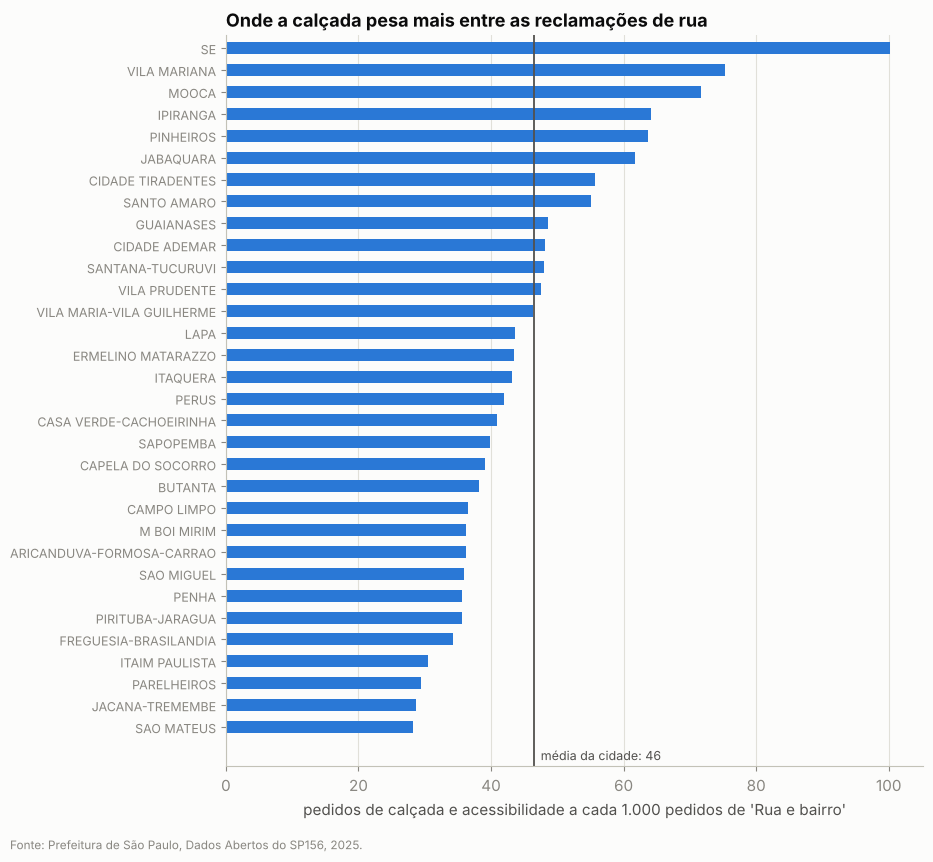

In [32]:
fig, ax = plt.subplots(figsize=(9, 9.5))
ordem = por_sub.sort_values("calcada_a_cada_mil")
ax.barh(ordem.index, ordem["calcada_a_cada_mil"], color=AZUL, height=0.55)
ax.axvline(media_cidade, color=TINTA_2, linewidth=1.3)
ax.text(media_cidade + 1, -1.3, f"média da cidade: {media_cidade:.0f}", color=TINTA_2, fontsize=9, va="center")
ax.set_ylim(-1.8, len(ordem) - 0.4)
ax.tick_params(axis="y", labelsize=9)
ax.grid(axis="y", visible=False)
ax.set_xlabel("pedidos de calçada e acessibilidade a cada 1.000 pedidos de 'Rua e bairro'")
ax.set_title("Onde a calçada pesa mais entre as reclamações de rua")
fonte(fig, "Fonte: Prefeitura de São Paulo, Dados Abertos do SP156, 2025.")
salvar(fig, "05_calcada_por_subprefeitura.png")
plt.show()

A concentração também aparece no mapa: cada hexágono soma os pedidos de calçada e acessibilidade feitos naquela área em 2025.

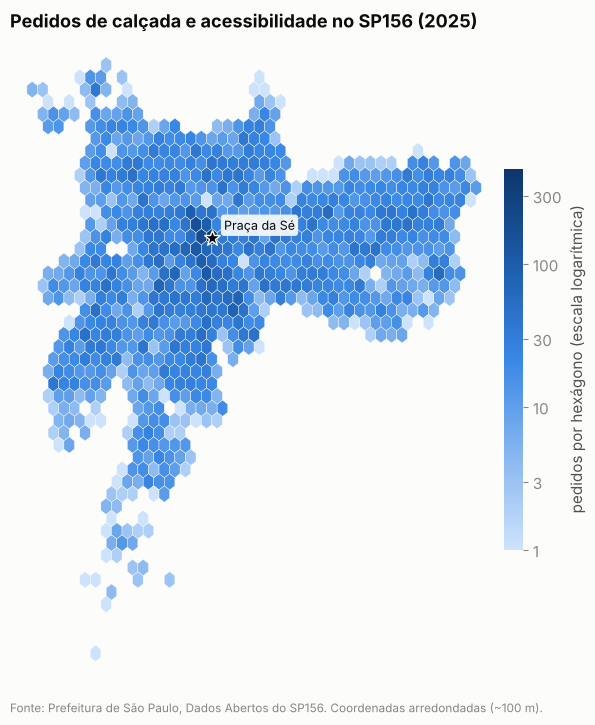

In [33]:
pontos = sp156[sp156["calcada"]].dropna(subset=["lat", "lon"])
fig, ax = plt.subplots(figsize=(7.5, 9))
hexagonos = ax.hexbin(pontos["lon"], pontos["lat"], gridsize=42, cmap=AZUIS, mincnt=1,
                      norm=LogNorm(), linewidths=0.3, edgecolors=FUNDO)   # escala log: a Sé não "apaga" o resto
ax.set_aspect(1 / np.cos(np.radians(23.6)))    # corrige a distorção entre graus de latitude e longitude
ax.plot(-46.634, -23.550, marker="*", color=TINTA, markersize=12, markeredgecolor=FUNDO, markeredgewidth=1)
ax.annotate("Praça da Sé", (-46.634, -23.550), xytext=(9, 6), textcoords="offset points", color=TINTA, fontsize=9,
            bbox=dict(boxstyle="round,pad=0.25", facecolor=FUNDO, edgecolor="none", alpha=0.9))
ax.set_xticks([])
ax.set_yticks([])
ax.grid(False)
for borda in ax.spines.values():
    borda.set_visible(False)
barra = fig.colorbar(hexagonos, ax=ax, shrink=0.55, pad=0.01)
barra.set_label("pedidos por hexágono (escala logarítmica)")
barra.set_ticks([1, 3, 10, 30, 100, 300])
barra.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}"))
barra.ax.minorticks_off()
barra.outline.set_visible(False)
ax.set_title("Pedidos de calçada e acessibilidade no SP156 (2025)")
fonte(fig, "Fonte: Prefeitura de São Paulo, Dados Abertos do SP156. Coordenadas arredondadas (~100 m).")
salvar(fig, "06_mapa_pedidos_calcada.png")
plt.show()

In [34]:
por_distrito = sp156[sp156["calcada"]].groupby("Distrito").size().sort_values(ascending=False)


def gini(valores):
    # 0 = todos os distritos com o mesmo número de pedidos; perto de 1 = tudo em poucos distritos
    x = np.sort(np.asarray(valores, dtype=float))
    n = len(x)
    return 2 * np.sum(np.arange(1, n + 1) * x) / (n * x.sum()) - (n + 1) / n


acumulado = por_distrito.cumsum() / por_distrito.sum()
print(f"{len(por_distrito)} distritos com pedidos. Os 10 com mais pedidos somam {pct(por_distrito.head(10).sum() / por_distrito.sum())} do total.")
print(f"Metade dos pedidos vem de {(acumulado < 0.5).sum() + 1} distritos. Índice de Gini = {gini(por_distrito):.2f}")
por_distrito.head(10).to_frame("pedidos de calçada")

96 distritos com pedidos. Os 10 com mais pedidos somam 20,9% do total.
Metade dos pedidos vem de 31 distritos. Índice de Gini = 0.26


,pedidos de calçada
Distrito,
SE,471
VILA MARIANA,386
ITAIM BIBI,339
JABAQUARA,331
ITAQUERA,321
SACOMA,305
SANTA CECILIA,283
SAUDE,282
PIRITUBA,276


**Interpretação:** H0 é rejeitada e **H3 se confirma**: a fatia de pedidos de calçada **varia muito entre as subprefeituras**, de 28 por mil (São Mateus) a 100 por mil (Sé), ou seja, **3,6 vezes**. As cinco maiores taxas estão em subprefeituras centrais (Sé, Vila Mariana, Mooca, Ipiranga e Pinheiros), onde mais gente anda a pé.

Dois cuidados na leitura:

* O **V de Cramér é pequeno (0,08)** porque calçada é só ~5% dos pedidos de rua; quando o desfecho é raro, essa medida fica baixa mesmo com diferenças grandes. Por isso a medida de efeito mais útil aqui é a **razão entre as taxas** (3,6 vezes).
* Uma reclamação mede **o problema e também quem reclama**. Taxa baixa na periferia não quer dizer calçada melhor: lá, outros problemas (buraco, drenagem, mato alto) dominam as reclamações, e há ruas sem calçada nenhuma. Em número absoluto, a concentração entre distritos é **moderada** (Gini 0,26: metade dos pedidos vem de cerca de um terço dos distritos).

O Caminho Livre terá o mesmo viés: o ranking de bairros (US14) deveria comparar regiões levando em conta o número de usuários ativos em cada uma, e não só o total de alertas.

## B.3 Quanto tempo leva para consertar?

No Caminho Livre, um alerta **sem confirmação expira em 15 dias** (RF14). Se a Prefeitura leva muito mais que isso para resolver um problema de calçada, o alerta pode sumir do mapa **antes** de o problema acabar.

Medimos quantos pedidos foram **finalizados em até 15 dias** depois de abertos. Essa medida conta como "não resolvido" quem ainda está aberto, então não favorece os casos rápidos. Usamos só os pedidos abertos no **1º semestre de 2025**: até a publicação dos dados (agosto de 2026) eles tiveram mais de um ano de acompanhamento. Comparamos com o tapa-buraco, o serviço mais pedido.

Ficou de fora "Construção de calçada": é uma sugestão, e quase todos esses pedidos são "finalizados" no mesmo dia. É um bom exemplo de que **"Finalizada" significa protocolo encerrado**, o que nem sempre quer dizer que o conserto foi feito.

In [35]:
DEFEITOS = ["Calçada pública: manutenção", "Calçada particular danificada ou inexistente",
            "Obstáculo na calçada (acessibilidade)", "Rebaixamento de guia (rampa)"]
semestre1 = sp156[sp156["abertura"] < "2025-07-01"].copy()
semestre1["grupo"] = semestre1["servico"].where(semestre1["servico"].isin(DEFEITOS))
semestre1.loc[semestre1["Serviço"] == "Tapa-buraco", "grupo"] = "Tapa-buraco (comparação)"
semestre1 = semestre1.dropna(subset=["grupo"])

finalizado = semestre1["Status"] == "Finalizada"
semestre1["dias"] = (semestre1["finalizacao"] - semestre1["abertura"]).dt.days.where(finalizado)
print("Status:", semestre1["Status"].value_counts().to_dict())
print("Finalizados com data inconsistente (fim antes do início):", (semestre1["dias"] < 0).sum())
semestre1.loc[semestre1["dias"] < 0, "dias"] = np.nan

tempos = semestre1.groupby("grupo").agg(
    pedidos=("dias", "size"),
    finalizados_ate_hoje=("Status", lambda s: (s == "Finalizada").mean()),
    resolvidos_em_ate_15_dias=("dias", lambda d: (d <= 15).mean()),     # aberto ou demorado conta como "não"
    mediana_dias_dos_finalizados=("dias", "median"),
).sort_values("resolvidos_em_ate_15_dias")
tempos.assign(finalizados_ate_hoje=tempos["finalizados_ate_hoje"].map(pct),
              resolvidos_em_ate_15_dias=tempos["resolvidos_em_ate_15_dias"].map(pct)).round(0)

Status: {'Finalizada': 68213, 'Aberto': 3555, 'Cancelada': 423, 'Em Andamento': 69}
Finalizados com data inconsistente (fim antes do início): 0


,pedidos,finalizados_ate_hoje,resolvidos_em_ate_15_dias,mediana_dias_dos_finalizados
grupo,,,,
Calçada particular danificada ou inexistente,2236,"45,3%","5,8%",112.0
Obstáculo na calçada (acessibilidade),2093,"41,0%","6,1%",91.0
Calçada pública: manutenção,3263,"89,6%","48,9%",12.0
Tapa-buraco (comparação),64322,"98,1%","65,9%",7.0
Rebaixamento de guia (rampa),346,"97,7%","70,5%",6.0


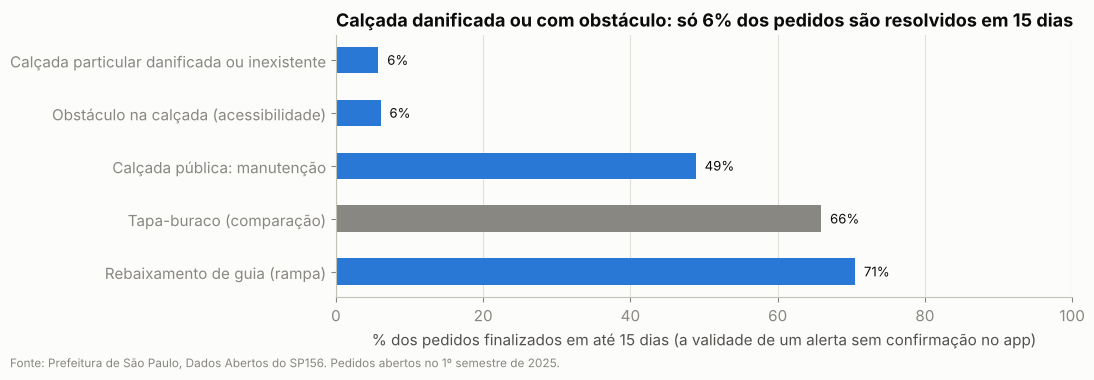

In [36]:
fig, ax = plt.subplots(figsize=(9.5, 3.4))
cores = [TINTA_SUAVE if "Tapa" in g else AZUL for g in tempos.index]
ax.barh(tempos.index, tempos["resolvidos_em_ate_15_dias"] * 100, color=cores, height=0.5)
for i, fatia in enumerate(tempos["resolvidos_em_ate_15_dias"]):
    ax.text(fatia * 100 + 1.2, i, pct(fatia, 0), va="center", color=TINTA, fontsize=9.5)
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("% dos pedidos finalizados em até 15 dias (a validade de um alerta sem confirmação no app)")
ax.set_title("Calçada danificada ou com obstáculo: só 6% dos pedidos são resolvidos em 15 dias")
fonte(fig, "Fonte: Prefeitura de São Paulo, Dados Abertos do SP156. Pedidos abertos no 1º semestre de 2025.")
salvar(fig, "07_resolvidos_em_15_dias.png")
plt.show()

# Conclusão

## Resultados

1. **H1 confirmada para roubo, não para furto.** Entre 19h e 23h acontecem **35,0%** dos roubos a pedestres (IC 95%: 34,7% a 35,4%), contra 20,8% se não houvesse concentração: **1,68 vez** o esperado (teste binomial, p < 0,001; w de Cohen = 0,40 nas 24 horas). Para furto, a fatia é 22,4% (1,07 vez): o teste rejeita H0 só porque a amostra é enorme. A chance de um roubo cair nessa faixa é **1,87 vez** a de um furto (IC 95%: 1,83 a 1,91). Há ainda um **segundo pico de roubo entre 4h e 6h**, de quem sai cedo para trabalhar. O resultado se mantém só com a conduta "Transeunte" (33,0%), em dias úteis (36,0%) e no fim de semana (32,4%).
2. **A escuridão pesa, não só o relógio.** Nos dias em que às 18h30 já é noite, a chance de um roubo acontecer às 18h (e não entre 12h e 15h) é **1,22 vez** maior (IC 95%: 1,14 a 1,32; p < 0,001). No controle das 20h, que é sempre noite, não há diferença (1,02; IC 95%: 0,96 a 1,09; p = 0,46). Mês a mês, quanto mais cedo anoitece, mais roubos às 18h (Spearman ρ = −0,88).
3. **Peso noturno de ~1,4.** Em 2025 houve 10,3 roubos a pedestres por hora de escuro e 7,2 por hora de dia: **1,43 vez** (IC 95% por bootstrap: 1,40 a 1,45). É um limite inferior do risco por pessoa, porque à noite há menos gente na rua.
4. **H3 confirmada, com ressalvas.** Os pedidos de calçada vão de 28 a cada mil pedidos de rua (São Mateus) a 100 a cada mil (Sé): **3,6 vezes** (qui-quadrado, p < 0,001). As maiores taxas estão nas subprefeituras centrais. Em número absoluto, a concentração entre distritos é moderada (Gini 0,26).
5. **Calçada demora a ser consertada.** Só **6%** dos pedidos de obstáculo na calçada e de calçada particular danificada foram finalizados em até 15 dias, e mais da metade continuava sem finalização mais de um ano depois. No tapa-buraco, são 66%.

## Limitações

* Boletim de ocorrência mede o crime **registrado**: há subnotificação, principalmente de furto, e ela pode variar por horário.
* A hora é estimada pela vítima (85% dos horários são múltiplos de 5 minutos) e 48% dos furtos não têm hora exata; por isso o resultado do furto é menos confiável que o do roubo.
* Sem dados de fluxo de pedestres por hora, as taxas são por hora do relógio, não por pessoa exposta.
* "Pedestre" foi inferido (via pública + conduta "Transeunte" ou "Outros") e pode incluir alguns casos que não são de pedestres.
* O experimento do pôr do sol é observacional: a rotina das pessoas também muda entre o verão e o inverno.
* Reclamação no SP156 mede o problema e também o hábito de reclamar, e os dados usados não têm a população de cada região. "Finalizada" é o fechamento do protocolo, não a garantia de conserto.
* A análise cobre um ano (2025) e uma cidade.

## Possível uso no Caminho Livre (futuro)

A análise é isolada e não muda o app agora, mas indica como calibrá-lo:

1. **Calibrar o `peso_noturno` do alerta "Assalto"** com pelo menos **1,4 vez** o `peso_base` (por exemplo, base 5 e noturno 7), ou usar o **índice por hora** da seção A.6, que capta o pico das 19h–22h (até 1,84) e o das 4h–6h.
2. **Definir a noite pelo pôr do sol, não pelo relógio.** Trocar a janela fixa 19h–6h pelo intervalo entre o anoitecer e o amanhecer de cada dia, que pode ser calculado só com a data. No inverno, o peso noturno passaria a valer a partir de ~17h50.
3. **Validade dos alertas por categoria (RF14).** 15 dias combina com buraco, mas é curto para calçada quebrada e obstáculo. Sugestão: validade maior (por exemplo, 90 dias) para os alertas de acessibilidade, ou expiração apenas por negações (👎).
4. **Ranking de bairros (US14) e lançamento.** Começar a divulgação pelas regiões centrais, onde há mais pedestres e mais reclamações de calçada, e comparar bairros pelo número de usuários ativos, para o mapa não refletir só quem reclama mais.
5. **Se um dia existir uma categoria "furto"**, ela não deveria ter peso noturno: o furto acompanha o movimento do dia.

**ODS:** os resultados apoiam a meta **11.7** (espaços públicos seguros, inclusivos e acessíveis, em especial para mulheres, idosos e pessoas com deficiência) e o **ODS 10** (reduzir desigualdades: o viés das reclamações para o centro mostra que o app precisa buscar ativamente os usuários da periferia).